In [1]:
import pandas as pd
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error
import datetime
from scipy import stats
from scipy.stats import shapiro, spearmanr, pearsonr, ttest_ind, mannwhitneyu

In [2]:
df = pd.read_csv('ecom_yl.csv')
df.head(5)

,User Id,Region,Device,Channel,Session Start,Session End,SessionDurationSec,Session Date,Month,Day,Hour of day,Order Dt,Revenue,Payment Type,Promo code
0,529697267522,United States,iPhone,социальные сети,2019-05-01 00:06:40,2019-05-01 00:07:06,26.0,2019-05-01,5,3,0,2019-05-01 00:06:40,9999.0,Mobile payments,0.0
1,601292388085,United States,PC,organic,2019-05-01 06:56:16,2019-05-01 07:09:18,782.0,2019-05-01,5,3,7,NaN,NaN,NaN,NaN
2,852898876338,United States,Mac,социальные сети,2019-05-01 04:30:45,2019-05-01 04:34:56,251.0,2019-05-01,5,3,4,NaN,NaN,NaN,NaN
3,998513020664,United States,iPhone,социальные сети,2019-05-01 18:53:42,2019-05-01 18:57:35,233.0,2019-05-01,5,3,18,NaN,NaN,NaN,NaN
4,240702200943,United States,Mac,социальные сети,2019-05-02 14:04:32,2019-05-02 14:09:51,319.0,2019-05-02,5,4,14,NaN,NaN,NaN,NaN


# Исследовательский анализ данных и предобработка

In [3]:
df.drop(['Session End', 'Session Date', 'Month', 'Day', 'Hour of day'], axis=1, inplace=True) 
# были удалены колонки, которые не понадобятся в будущем
df['Session Start'] = pd.to_datetime(df['Session Start'])
df['Order Dt'] = pd.to_datetime(df['Order Dt']) # перевод в удобный формат данных
df.columns = df.columns.str.lower().str.replace(' ', '_') # перевод в PEP8

In [4]:
df['region'] = df['region'].apply(lambda x: 'United States' if x == 'Unjted States' else x)
df['region'] = df['region'].apply(lambda x: 'Germany' if x == 'germany' else x)
df['region'] = df['region'].apply(lambda x: 'France' if x == 'France' or x == 'Frаnce' or x == 'Frаncе' or x == 'Franсe' else x)
df['region'] = df['region'].apply(lambda x: 'UK' if x == 'UК' else x)
df['device'] = df['device'].apply(lambda x: 'Android' if x == 'android' else x)
df['channel'] = df['channel'].apply(lambda x: 'контекстная реклама' if x == 'контексная реклама' else x)
df['promo_code'] = df['promo_code'].apply(lambda x: 1 if x != 1 and x != 0 else x) # устранение некоретных записей

Были устранены опечатки из-за которых одинаковые записи разбивались на разные

In [5]:
df['part_of_day'] = df['session_start'].dt.hour.apply(lambda x: 'утро' if x >= 6 and x < 10 
                                                      else('день' if x >= 10 and x < 17
                                                          else('вечер' if x >= 17 and x < 22
                                                              else 'ночь'))) # создание столбца с частью дня

In [6]:
df['revenue'] = df['revenue'] * (1 - df['promo_code'] / 10)
df['payer'] = df['revenue'].isna().apply(lambda x: 1 if x == False else 0) # применена скидка для платящих

In [7]:
df.drop(df[df.duplicated()].index, inplace=True)
df.reset_index(inplace=True)
df.drop('index', axis=1, inplace=True) # убраны дубликаты

propuski = ['user_id', 'region', 'device', 'channel', 'session_start', 'sessiondurationsec']
df.drop(df[propuski][df[propuski].isnull().any(axis=1)].index, inplace=True)
df.reset_index(inplace=True)
df.drop('index', axis=1, inplace=True) # убраны незначащие пропуски из этих столбцов

In [8]:
print(df.sort_values('session_start')['session_start'].dt.month.value_counts()) 
print()
print(df.groupby(df['session_start'].dt.month)['channel'].value_counts())
# на основании этого было принято решение использовать весь срок для исследования

8     187
9     184
10    182
6     154
5     146
7     144
Name: session_start, dtype: int64

session_start  channel            
5              organic                76
               социальные сети        41
               реклама у блогеров     14
               контекстная реклама     8
               email-рассылки          7
6              organic                59
               социальные сети        53
               контекстная реклама    28
               реклама у блогеров     13
               email-рассылки          1
7              социальные сети        56
               organic                46
               контекстная реклама    24
               реклама у блогеров     15
               email-рассылки          3
8              социальные сети        68
               organic                60
               контекстная реклама    35
               реклама у блогеров     20
               email-рассылки          4
9              социальные сети        66
         

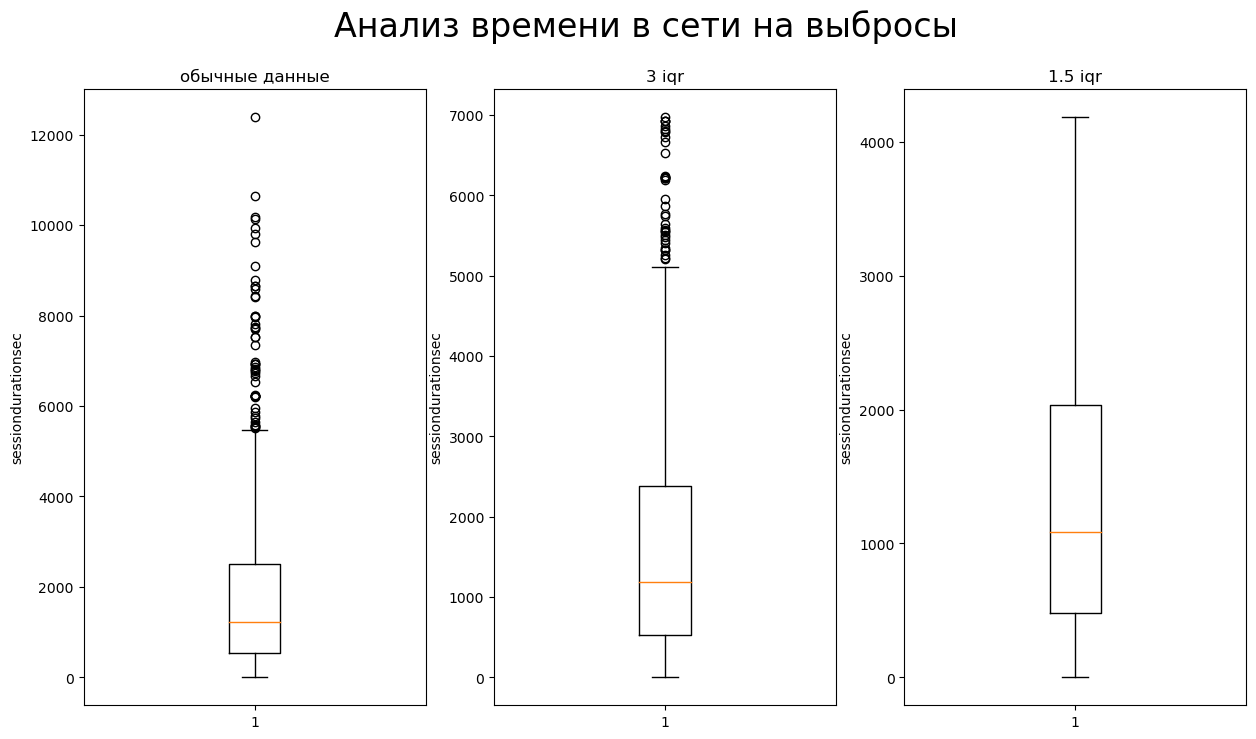

In [9]:
f, ax = plt.subplots(1, 3, figsize=(15, 8))

ax[0].boxplot(df.sessiondurationsec)
ax[0].set_title('обычные данные')
ax[0].set_ylabel('sessiondurationsec')

iqr = np.quantile(df.sessiondurationsec, 0.75) - np.quantile(df.sessiondurationsec, 0.25)
top = df.sessiondurationsec.median() + 3 * iqr
n = sum(df.sessiondurationsec > top)
ax[1].boxplot(df.sessiondurationsec.sort_values()[0: len(df.sessiondurationsec) - n])
ax[1].set_title('3 iqr')
ax[1].set_ylabel('sessiondurationsec')

iqr = np.quantile(df.sessiondurationsec, 0.75) - np.quantile(df.sessiondurationsec, 0.25)
top = df.sessiondurationsec.median() + 1.5 * iqr
n = sum(df.sessiondurationsec > top)
ax[2].boxplot(df.sessiondurationsec.sort_values()[0: len(df.sessiondurationsec) - n])
ax[2].set_title('1.5 iqr')
ax[2].set_ylabel('sessiondurationsec')
f.suptitle('Анализ времени в сети на выбросы', fontsize=24)

plt.savefig('sessiondurationsec') # графическая проверка выбросов

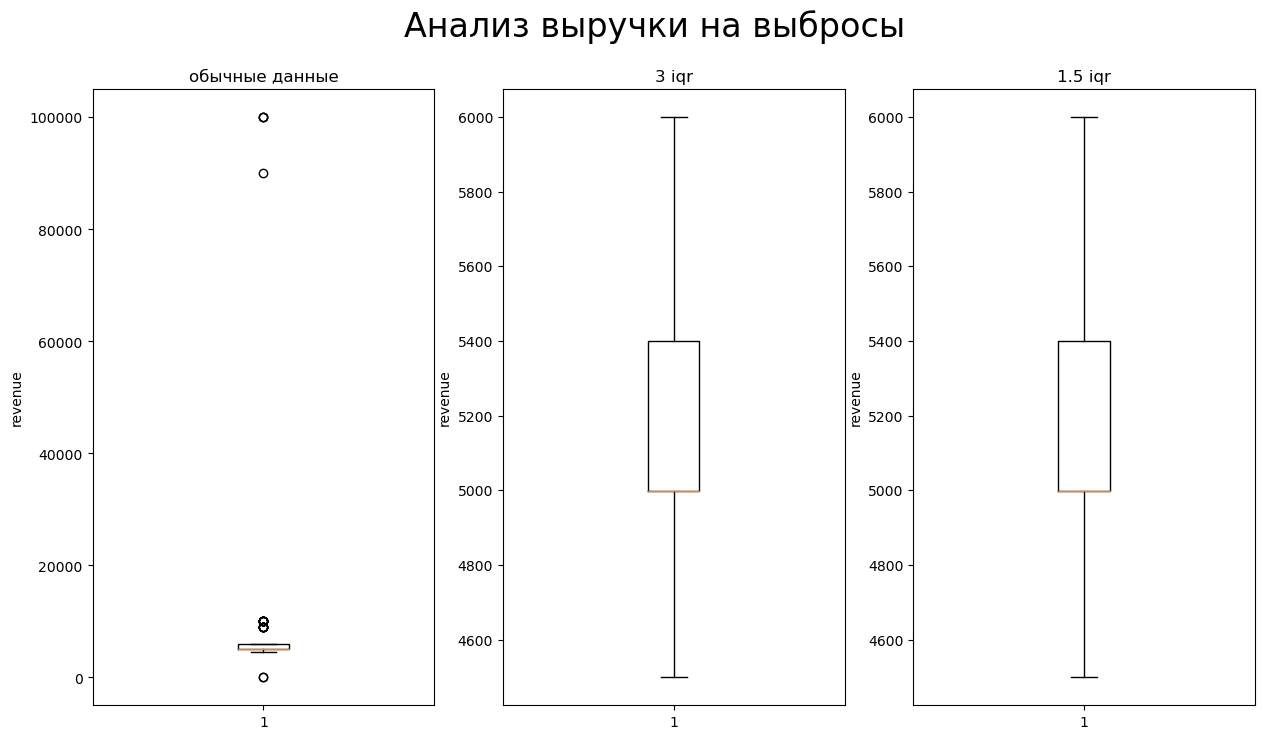

In [10]:
f, ax = plt.subplots(1, 3, figsize=(15, 8))

ax[0].boxplot(df.revenue.dropna())
ax[0].set_title('обычные данные')
ax[0].set_ylabel('revenue')

iqr = np.quantile(df.revenue.dropna(), 0.75) - np.quantile(df.revenue.dropna(), 0.25)
top = df.revenue.dropna().median() + 3 * iqr
n = sum(df.revenue.dropna() > top)
ax[1].boxplot(df.revenue.dropna().sort_values()[2: len(df.revenue.dropna()) - n])
ax[1].set_title('3 iqr')
ax[1].set_ylabel('revenue')

iqr = np.quantile(df.revenue.dropna(), 0.75) - np.quantile(df.revenue.dropna(), 0.25)
top = df.revenue.dropna().median() + 1.5 * iqr
n = sum(df.revenue.dropna() > top)
ax[2].boxplot(df.revenue.dropna().sort_values()[2: len(df.revenue.dropna()) - n])
ax[2].set_title('1.5 iqr')
ax[2].set_ylabel('revenue')
f.suptitle('Анализ выручки на выбросы', fontsize=24)

plt.show()

In [11]:
iqr = np.quantile(df.sessiondurationsec, 0.75) - np.quantile(df.sessiondurationsec, 0.25)
top = df.sessiondurationsec.median() + 3 * iqr
dn = df[df['sessiondurationsec'] < top]

iqr = np.quantile(df.revenue.dropna(), 0.75) - np.quantile(df.revenue.dropna(), 0.25)
top = df.revenue.dropna().median() + 3 * iqr
dn = dn[(dn['revenue'] < top) & (dn['revenue'] > 1) | (dn['revenue'].isna() == True)]

dn.reset_index(inplace=True)
dn.drop('index', axis=1, inplace=True) #удалено менее 5% выбросов по количественным данным на основе 3 интерквартильных размахов

На осоновании графического и аналитического анализа были исключены выбросы на основе 3 интерквартильных размахов по 2 количественным переменным, так как они бы очень сильно повлияли на среднее. Всего было удалено менее 5% всех данных

In [12]:
dn['payer'] = dn['revenue'].isna().apply(lambda x: 1 if x == False else 0) # создан новый столбец

In [13]:
dn[dn.revenue.isna()==False]['payment_type'].value_counts()
# проверка распределения покупок по типу оплаты

Mobile payments    68
E-wallet           59
Cash               53
Credit card        32
Debit card         31
Name: payment_type, dtype: int64

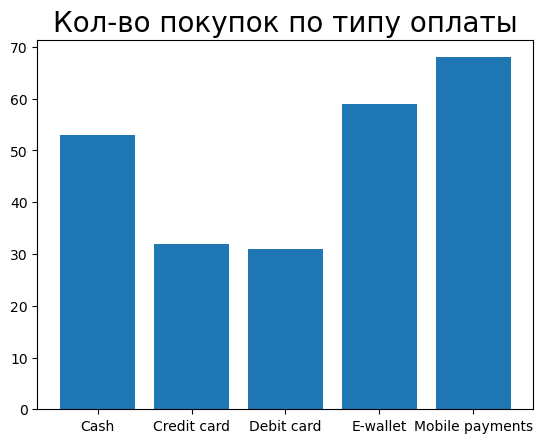

In [14]:
plt.bar(dn.groupby(dn['payment_type'])['payer'].sum().index, 
        dn.groupby(dn['payment_type'])['payer'].sum())
plt.title('Кол-во покупок по типу оплаты', fontsize=20)
plt.show()
# и графическая интерпретация

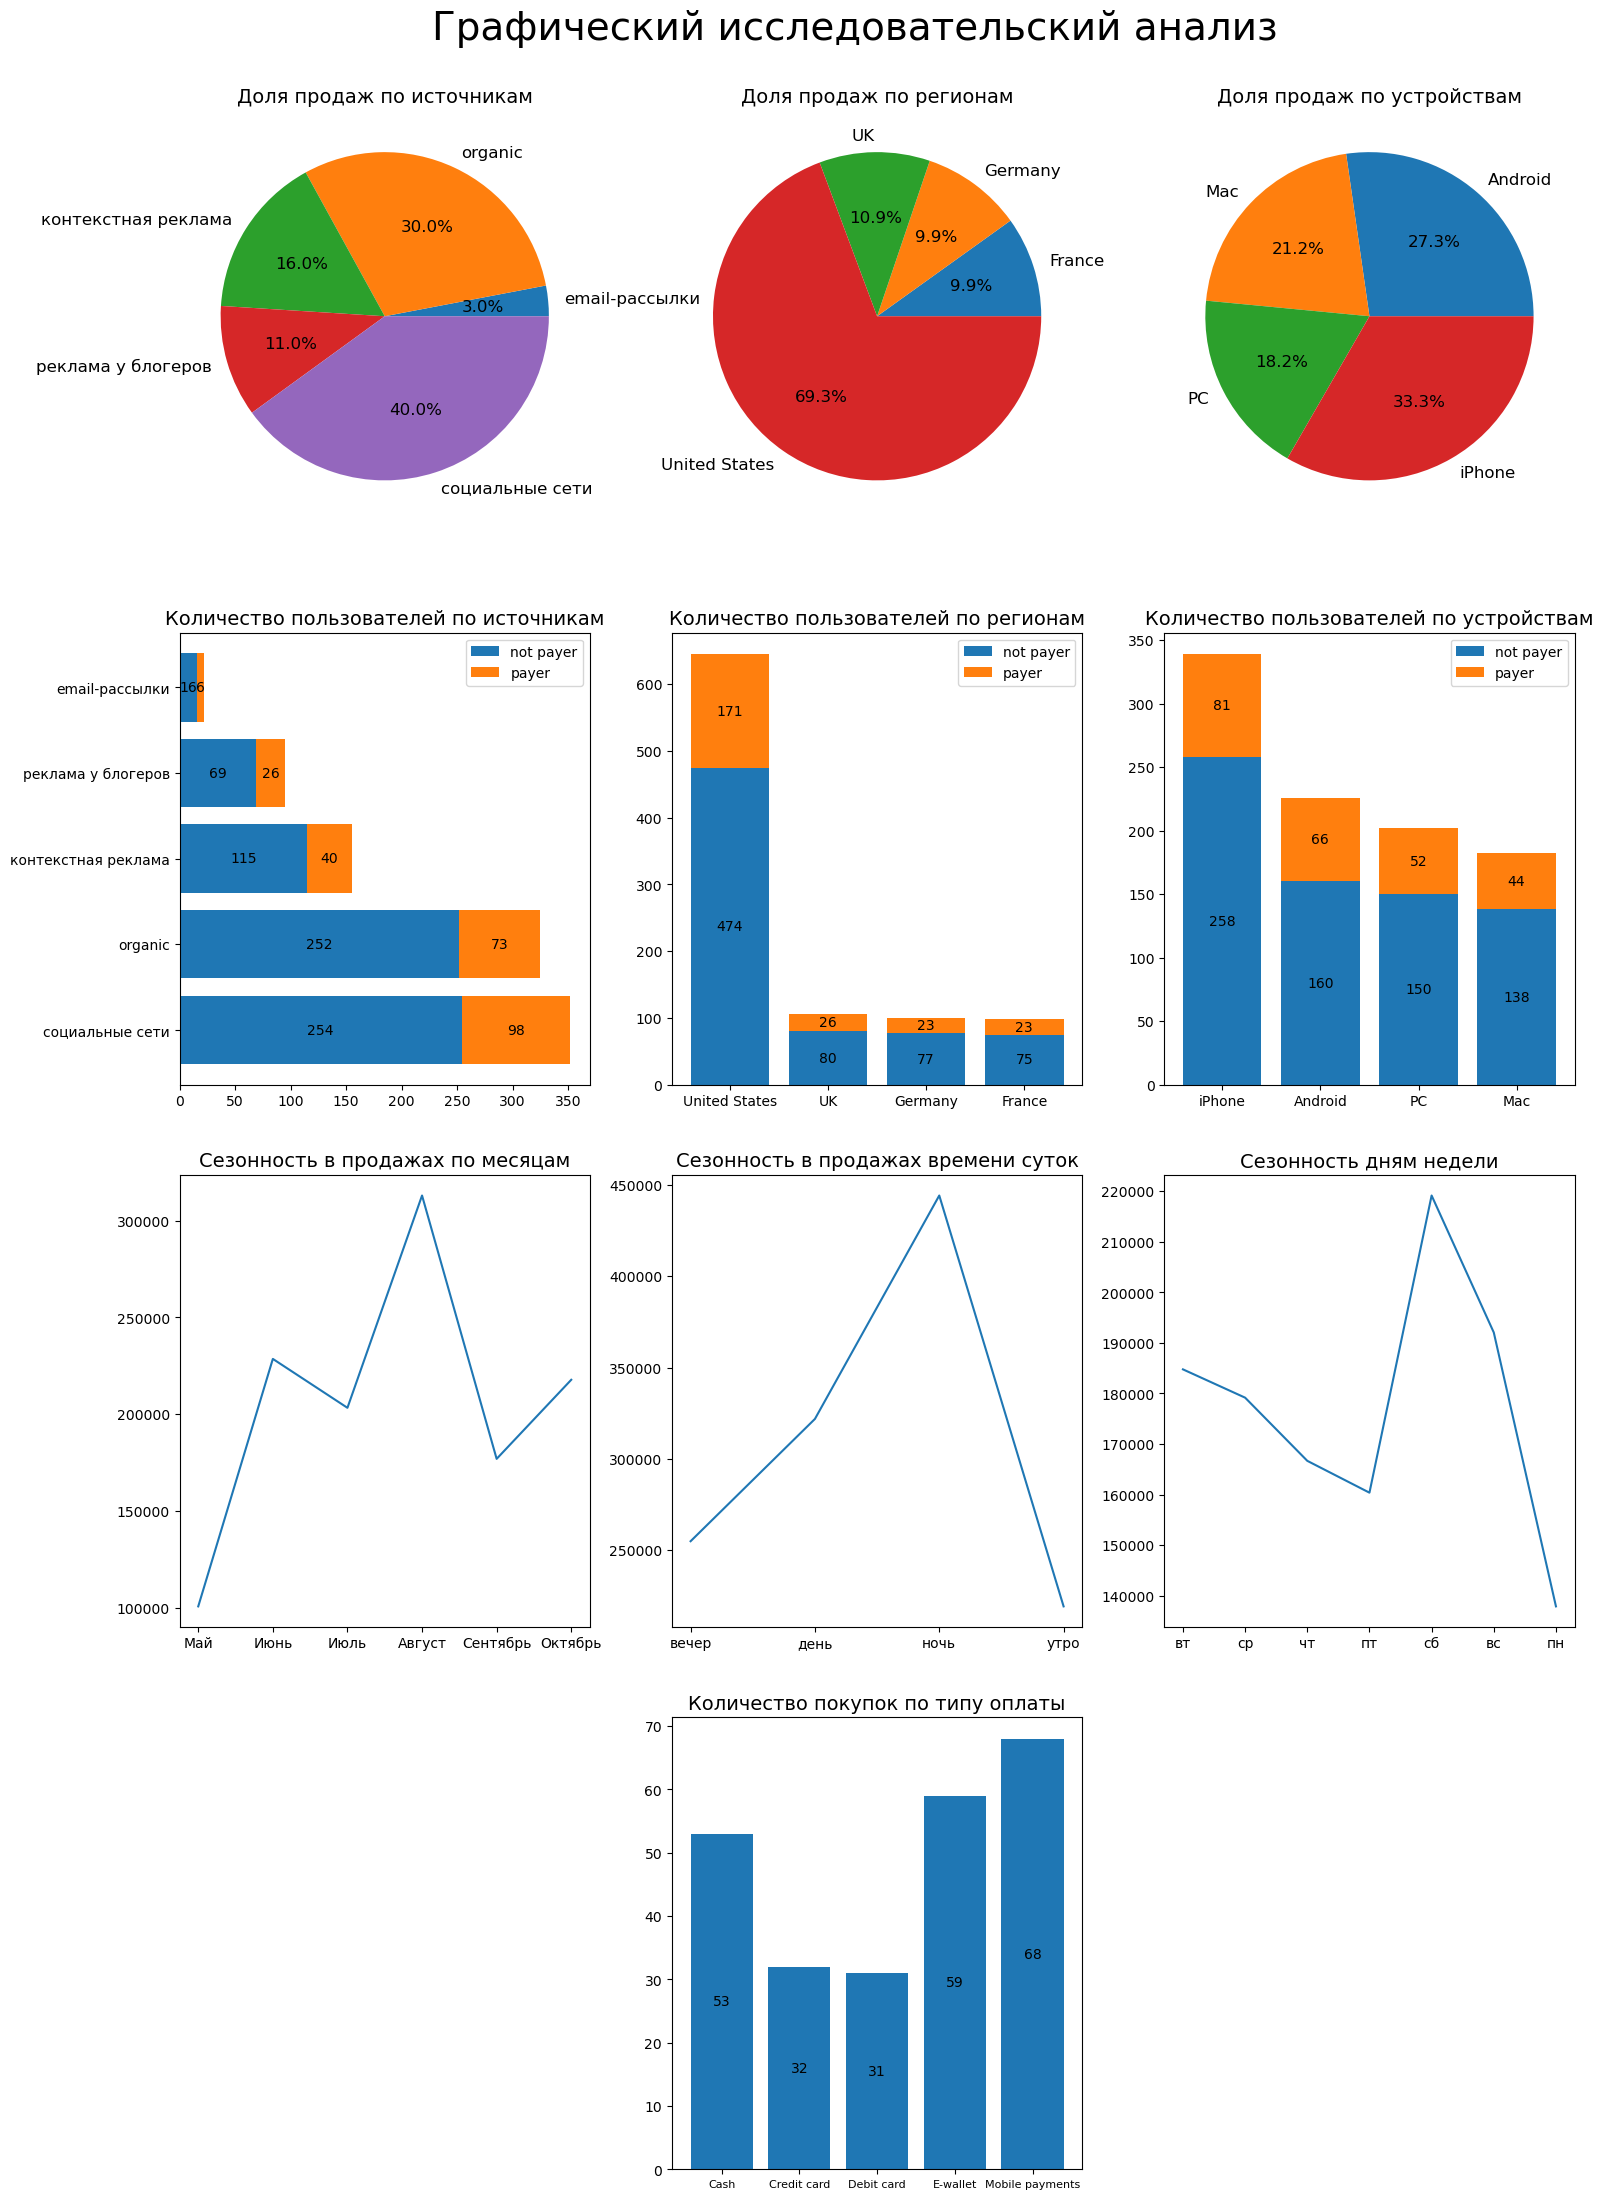

In [15]:
f, ax = plt.subplots(4, 3, figsize=(18, 27))

ax[0][1].pie(round(dn.groupby('region')['revenue'].sum() / dn.revenue.dropna().sum(), 2), 
        labels=dn.groupby('region')['revenue'].sum().index, 
        autopct='%1.1f%%', 
        textprops={'fontsize': 12})
ax[0][1].set_title('Доля продаж по регионам', fontsize=14)

ax[0][0].pie(round(dn.groupby('channel')['revenue'].sum() / dn.revenue.dropna().sum(), 2), 
        labels=dn.groupby('channel')['revenue'].sum().index, 
        autopct='%1.1f%%', 
        textprops={'fontsize': 12})
ax[0][0].set_title('Доля продаж по источникам', fontsize=14)

ax[0][2].pie(round(dn.groupby('device')['revenue'].sum() / dn.revenue.dropna().sum(), 2), 
        labels=dn.groupby('device')['revenue'].sum().index, 
        autopct='%1.1f%%', 
        textprops={'fontsize': 12})
ax[0][2].set_title('Доля продаж по устройствам', fontsize=14)

p1 = ax[1][1].bar(dn['region'].value_counts().index,
        dn[dn['payer'] == 0]['region'].value_counts())
p2 = ax[1][1].bar(dn['region'].value_counts().index,
        dn[dn['payer'] == 1]['region'].value_counts(), 
        bottom = dn[dn['payer'] == 0]['region'].value_counts())
ax[1][1].bar_label(p2, label_type='center')
ax[1][1].bar_label(p1, label_type='center')
ax[1][1].legend((p1[0], p2[0]), ('not payer', 'payer'))
ax[1][1].set_title('Количество пользователей по регионам', fontsize=14)

p1 = ax[1][0].barh(dn['channel'].value_counts().index,
        dn[dn['payer'] == 0]['channel'].value_counts())
p2 = ax[1][0].barh(dn['channel'].value_counts().index,
        dn[dn['payer'] == 1]['channel'].value_counts(), 
        left = dn[dn['payer'] == 0]['channel'].value_counts())
ax[1][0].bar_label(p2, label_type='center')
ax[1][0].bar_label(p1, label_type='center')
ax[1][0].legend((p1[0], p2[0]), ('not payer', 'payer'))
ax[1][0].set_title('Количество пользователей по источникам', fontsize=14)

p1 = ax[1][2].bar(dn['device'].value_counts().index,
        dn[dn['payer'] == 0]['device'].value_counts())
p2 = ax[1][2].bar(dn['device'].value_counts().index,
        dn[dn['payer'] == 1]['device'].value_counts(), 
        bottom = dn[dn['payer'] == 0]['device'].value_counts())
ax[1][2].bar_label(p2, label_type='center')
ax[1][2].bar_label(p1, label_type='center')
ax[1][2].legend((p1[0], p2[0]), ('not payer', 'payer'))
ax[1][2].set_title('Количество пользователей по устройствам', fontsize=14)

ax[2][0].plot(['Май', 'Июнь', 'Июль', 'Август', 'Сентябрь', 'Октябрь'], 
         dn.groupby(dn['session_start'].dt.month)['revenue'].sum())
ax[2][0].set_title('Сезонность в продажах по месяцам', fontsize=14)

ax[2][1].plot(dn.groupby(dn['part_of_day'])['revenue'].sum().index, 
         dn.groupby(dn['part_of_day'])['revenue'].sum())
ax[2][1].set_title('Сезонность в продажах времени суток', fontsize=14)

ax[2][2].plot(['вт', 'ср', 'чт', 'пт', 'сб', 'вс', 'пн'], 
         dn.groupby(dn['session_start'].dt.dayofweek)['revenue'].sum())
ax[2][2].set_title('Cезонность дням недели', fontsize=14)

p = ax[3][1].bar(dn.groupby(dn['payment_type'])['payer'].sum().index, 
        dn.groupby(dn['payment_type'])['payer'].sum())
ax[3][1].set_title('Количество покупок по типу оплаты', fontsize=14)
ax[3][1].bar_label(p, label_type='center')
ax[3][1].tick_params(axis='x', labelsize=8)

f.delaxes(ax[3][2])
f.delaxes(ax[3][0])
f.suptitle('Графический исследовательский анализ', fontsize=28, y=0.91)

plt.show() 
# построены графики, обобщающие развед анализ, благодаря которым становится в целом понятно с какими данными мы будем работать

На основании данных, мы можем сделать предварительный вывод, что больше всего нам придется работать с людьми из США, использующими мобильные телефоны для покупки.

# Проведение расчётов

Средний чек 5103.1



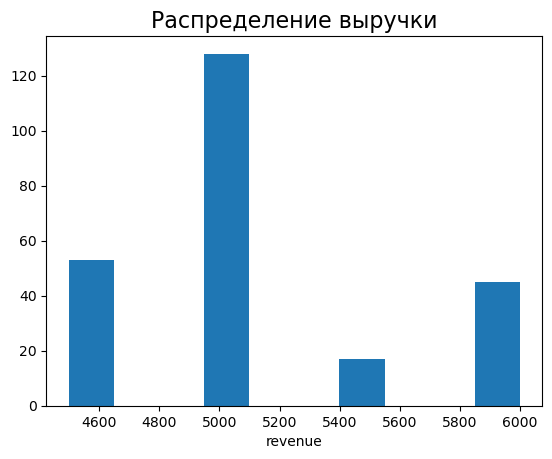


Среднее кол-во покупок на одного пользователя 0.256



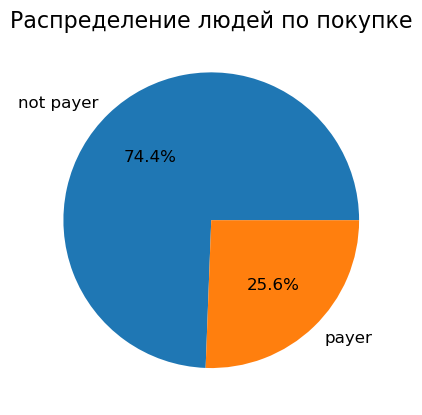


Средняя продолжительность сессии по рекламным каналам:
контекстная реклама 1851.0
 реклама у блогеров 1706.0
     email-рассылки 1643.0
            organic 1625.0
    социальные сети 1567.0



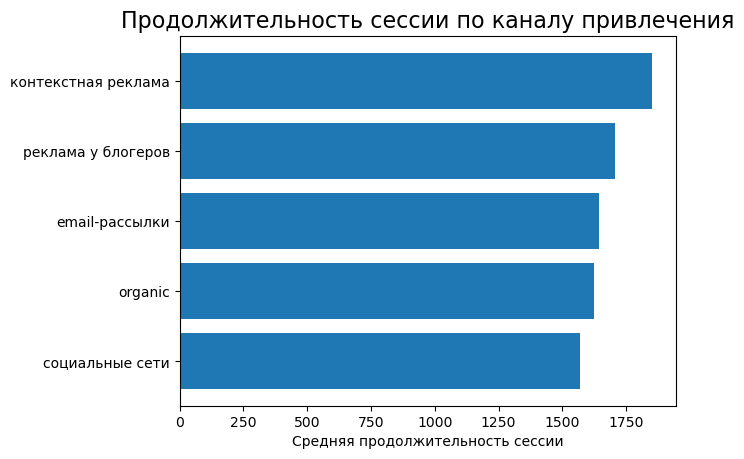


 по типу устройства:
     PC 1747.0
Android 1724.0
    Mac 1583.0
 iPhone 1579.0



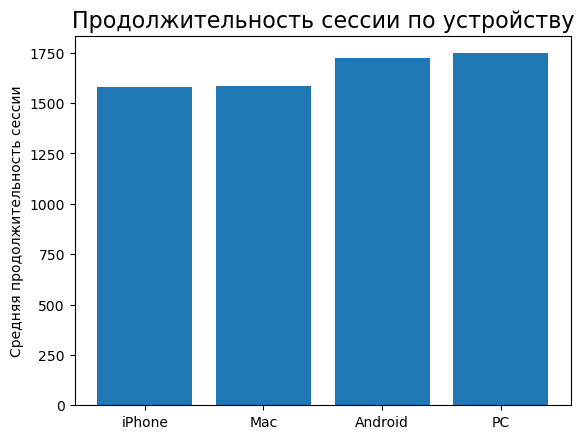


Топ-3 рекламных канала по среднему чеку:
    email-рассылки 5332.0
реклама у блогеров 5241.0
   социальные сети 5110.0



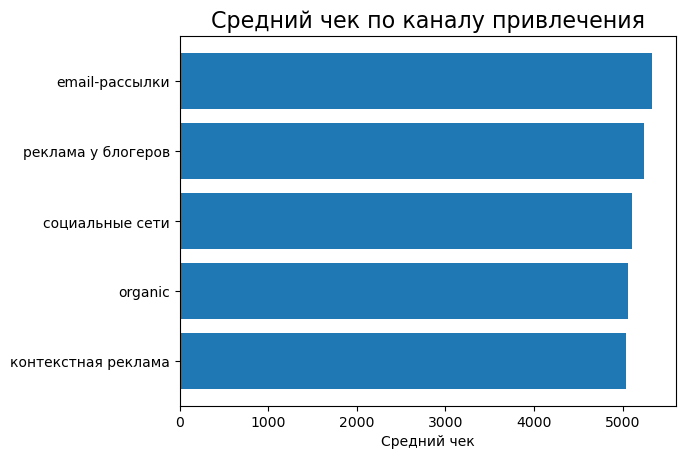


Топ-3 региона  по среднему чеку:
 France 5256.0
     UK 5203.0
Germany 5143.0



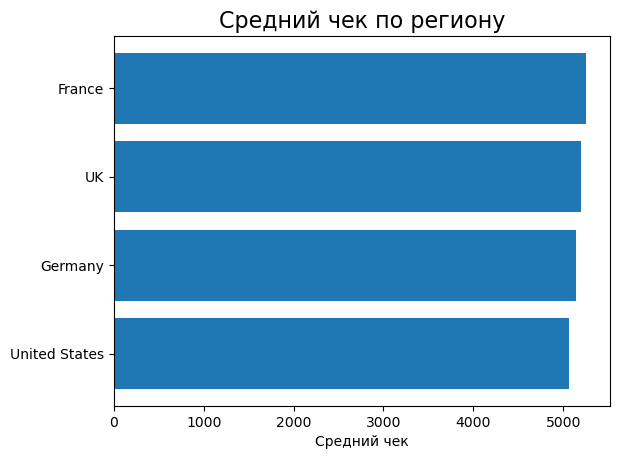


Топ-3 месяца по среднему чеку с разбивкой по регионам:
   Май        France 5499.0
   Май       Germany 5679.0
   Май            UK 5149.0
   Май United States 5030.0
  Июнь        France 4999.0
  Июнь       Germany 4999.0
  Июнь            UK 5199.0
  Июнь United States 5069.0
Август        France 4999.0
Август       Germany 4988.0
Август            UK 5142.0
Август United States 5175.0



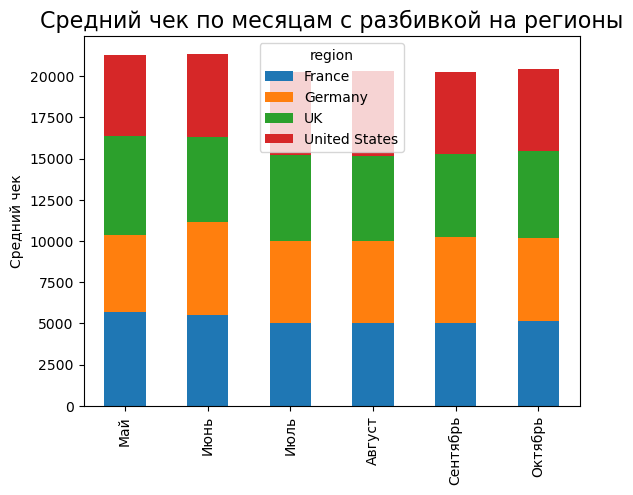


MAU по каждому месяцу с разбивкой по рекламным каналам
     Май             organic 69
     Май     социальные сети 36
     Май  реклама у блогеров 10
     Май контекстная реклама  8
     Май      email-рассылки  7
    Июнь             organic 55
    Июнь     социальные сети 49
    Июнь контекстная реклама 28
    Июнь  реклама у блогеров 12
    Июнь      email-рассылки  1
    Июль     социальные сети 55
    Июль             organic 45
    Июль контекстная реклама 24
    Июль  реклама у блогеров 15
    Июль      email-рассылки  3
  Август     социальные сети 65
  Август             organic 57
  Август контекстная реклама 32
  Август  реклама у блогеров 20
  Август      email-рассылки  4
Сентябрь     социальные сети 64
Сентябрь             organic 56
Сентябрь контекстная реклама 38
Сентябрь  реклама у блогеров 20
Сентябрь      email-рассылки  2
 Октябрь     социальные сети 83
 Октябрь             organic 43
 Октябрь контекстная реклама 25
 Октябрь  реклама у блогеров 18
 Октябрь      em

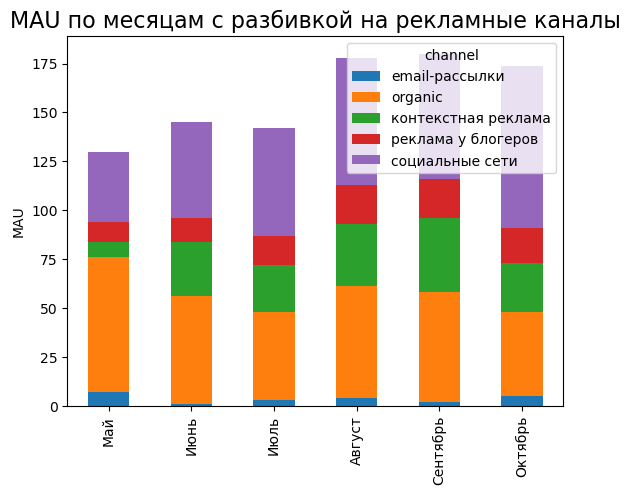


Топ-3 канала по кол-ву уникальных пользователей в месяц:
социальные сети        58
organic                54
контекстная реклама    25



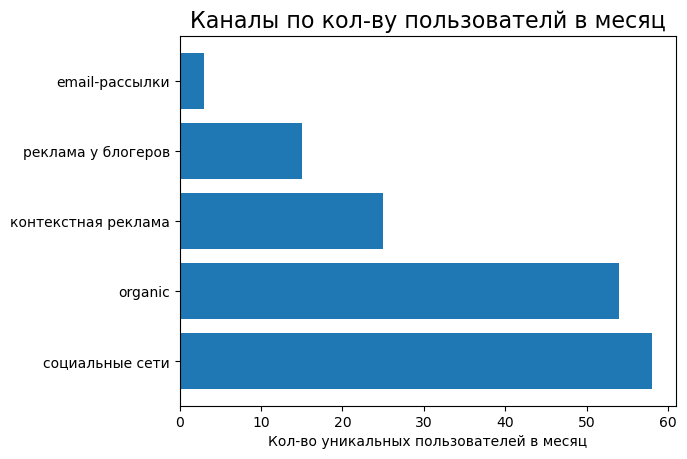

In [16]:
print('Средний чек', round(sum(dn.revenue.dropna()) / len(dn[dn.payer == 1]['payer']), 1))
plt.hist(dn.revenue.dropna(), bins=10)
plt.xlabel('revenue')
plt.title('Распределение выручки', fontsize=16)
print()
plt.show()
print()

print('Среднее кол-во покупок на одного пользователя', round(len(dn[dn.payer == 1]['payer']) / len(dn.payer), 3))
plt.pie(dn.payer.value_counts(), labels=['not payer', 'payer'], 
        autopct='%1.1f%%', 
        textprops={'fontsize': 12})
print()
plt.title('Распределение людей по покупке', fontsize=16)
plt.show()
print()

print('Средняя продолжительность сессии по рекламным каналам:')
print(round(dn.groupby('channel', as_index=False)['sessiondurationsec'].mean()).sort_values('sessiondurationsec', 
                                                                    ascending=False).to_string(index=False, header=False))
plt.barh(dn.groupby('channel', as_index=False)['sessiondurationsec'].mean().sort_values('sessiondurationsec')['channel'],
        dn.groupby('channel', as_index=False)['sessiondurationsec'].mean().sort_values('sessiondurationsec')['sessiondurationsec'])
plt.xlabel("Средняя продолжительность сессии")
plt.title('Продолжительность сессии по каналу привлечения', fontsize=16)
print()
plt.show()
print()

print(' по типу устройства:')
print(round(dn.groupby('device', as_index=False)['sessiondurationsec'].mean()).sort_values('sessiondurationsec', 
                                                                    ascending=False).to_string(index=False, header=False))
plt.bar(dn.groupby('device', as_index=False)['sessiondurationsec'].mean().sort_values('sessiondurationsec')['device'],
        dn.groupby('device', as_index=False)['sessiondurationsec'].mean().sort_values('sessiondurationsec')['sessiondurationsec'])
plt.ylabel("Средняя продолжительность сессии")
plt.title('Продолжительность сессии по устройству', fontsize=16)
print()
plt.show()
print()

print('Топ-3 рекламных канала по среднему чеку:')
print(round(dn[dn.revenue.isna() == False].groupby('channel', as_index=False)['revenue'].mean(), 0).sort_values('revenue', 
                            ascending=False).reset_index().drop('index', axis=1).head(3).to_string(index=False, header=False))
plt.barh(dn[dn.revenue.isna() == False].groupby('channel', as_index=False)['revenue'].mean().sort_values('revenue')['channel'],
        dn[dn.revenue.isna() == False].groupby('channel', as_index=False)['revenue'].mean().sort_values('revenue')['revenue'])
plt.xlabel("Средний чек")
plt.title('Средний чек по каналу привлечения', fontsize=16)
print()
plt.show()
print()

print('Топ-3 региона  по среднему чеку:')
print(round(dn[dn.revenue.isna() == False].groupby('region', as_index=False)['revenue'].mean(), 0).sort_values('revenue', 
                            ascending=False).reset_index().drop('index', axis=1).head(3).to_string(index=False, header=False))
plt.barh(dn[dn.revenue.isna() == False].groupby('region', as_index=False)['revenue'].mean().sort_values('revenue')['region'],
        dn[dn.revenue.isna() == False].groupby('region', as_index=False)['revenue'].mean().sort_values('revenue')['revenue'])
plt.xlabel("Средний чек")
plt.title('Средний чек по региону', fontsize=16)
print()
plt.show()
print()

print('Топ-3 месяца по среднему чеку с разбивкой по регионам:')
dn['month'] = dn.session_start.dt.month
mon = dn[dn.revenue.isna() == False].groupby(['month'], as_index=False)['revenue'].mean().sort_values('revenue', 
                                                    ascending=False).head(3).reset_index().drop('index', axis=1).month
a = round(dn[(dn.revenue.isna() == False) & (dn.month == mon[0]) | (dn.month == mon[1]) | (dn.month == mon[2])].groupby(['month',
                                                'region'], as_index=False)['revenue'].mean())
a.month = dn[(dn.revenue.isna() == False) & (dn.month == 5) | (dn.month == 6) | (dn.month == 8)].groupby(['month', 'region'], 
            as_index=False)['revenue'].mean().month.apply(lambda x: 'Май' if x == 5 else('Июнь' if x == 6 else ('Июль' if x == 7 else('Август' if x == 8 else('Сентябрь' if x == 9 else 'Октябрь')))))
print(a.to_string(index=False, header=False))
k = dn.groupby(['month', 'region'])['revenue'].mean().unstack()
k.index = ['Май', 'Июнь', 'Июль', 'Август', 'Сентябрь', 'Октябрь']
k.plot(kind='bar', stacked=True)
plt.ylabel("Средний чек")
plt.title('Средний чек по месяцам с разбивкой на регионы', fontsize=16)
print()
plt.show()
print()

print('MAU по каждому месяцу с разбивкой по рекламным каналам')
mn = dn.groupby('month')['channel'].value_counts().rename_axis(['month', 'channel']).reset_index(name='counts')
mn.month = mn.month.apply(lambda x: 'Май' if x == 5 else('Июнь' if x == 6 else ('Июль' if x == 7 else('Август' if x == 8 else('Сентябрь' if x == 9 else 'Октябрь')))))
print(mn.to_string(index=False, header=False))
k = dn.groupby('month')['channel'].value_counts().unstack()
k.index = ['Май', 'Июнь', 'Июль', 'Август', 'Сентябрь', 'Октябрь']
k.plot(kind='bar', stacked=True)
print()
plt.ylabel("MAU")
plt.title('MAU по месяцам с разбивкой на рекламные каналы', fontsize=16)
plt.show()
print()

print('Топ-3 канала по кол-ву уникальных пользователей в месяц:')
k = dn.channel.value_counts() // dn.month.nunique()
print(k[0: 3].to_string())
print()
plt.barh(k.index, k)
plt.xlabel("Кол-во уникальных пользователей в месяц")
plt.title('Каналы по кол-ву пользователй в месяц', fontsize=16)
plt.show()
dn.drop('month', axis=1, inplace=True)
# сделаны все необходимые вычисления и приведена графическая интерпретация для каждого

Получены выводы: большая часть людей приходят благодаря социальным сетям и естественному приросту, кол-во пользователей значительно различается в зависимости от месяца, в среднем покупает примерно каждый 4 человек.

# Создание таблицы по рекламным каналам и регионам

In [26]:
mau = pd.DataFrame()
mau = dn['channel'].value_counts().sort_index().rename_axis('канал').reset_index(name='кол-во пользователей')
mau['уникальных'] = mau['кол-во пользователей']
mau['платящих'] = dn.groupby('channel')['payer'].sum().to_list()
mau['сумма выручки'] = round(dn.dropna().groupby('channel')['revenue'].sum()).astype(int).to_list()
print(mau.sort_values('сумма выручки', ascending=False).to_string(index=False))
print()
print('Больше всего платящих пользователей по каналу')
print(mau.sort_values('платящих').tail(1).канал.to_string(index=False))
print()
print('Больше всего выручка по каналу')
print(mau.sort_values('сумма выручки').tail(1).канал.to_string(index=False))
print()

mau = pd.DataFrame()
mau = dn['region'].value_counts().sort_index().rename_axis('region').reset_index(name='кол-во пользователей')
mau['уникальных'] = mau['кол-во пользователей']
mau['платящих'] = dn.groupby('region')['payer'].sum().to_list()
mau['сумма выручки'] = round(dn.dropna().groupby('region')['revenue'].sum()).astype(int).to_list()
print(mau.sort_values('сумма выручки', ascending=False).to_string(index=False))
print()
print('Больше всего платящих пользователей по региону')
print(mau.sort_values('платящих').tail(1).region.to_string(index=False))
print()
print('Больше всего выручка по региону')
print(mau.sort_values('сумма выручки').tail(1).region.to_string(index=False))
# создан новый датафрейм для выполнения задания

              канал  кол-во пользователей  уникальных  платящих  сумма выручки
    социальные сети                   352         352        98         500804
            organic                   325         325        73         369330
контекстная реклама                   155         155        40         201661
 реклама у блогеров                    95          95        26         136274
     email-рассылки                    22          22         6          31994

Больше всего платящих пользователей по каналу
социальные сети

Больше всего выручка по каналу
социальные сети

       region  кол-во пользователей  уникальных  платящих  сумма выручки
United States                   645         645       171         865634
           UK                   106         106        26         135274
       France                    98          98        23         120878
      Germany                   100         100        23         118278

Больше всего платящих пользователей по региону
U

Благодаря этой табличке мы получаем конкретные данные по каждому из рекламных каналов, в частности стоит отметить, что количество уникальных пользователей равно количеству пользователей, следовательно все пользователи являютcя уникальными. Также была построена таблица по регионам.

# Регрессионное моделирование

In [18]:
dr = dn[['region', 'device', 'channel', 'sessiondurationsec', 'revenue', 'part_of_day']]
encoder = OneHotEncoder(handle_unknown="ignore")
encoder_df = pd.DataFrame(encoder.fit_transform(dr[["region", 'device', 'channel', 'part_of_day']]).toarray())
final_df = dr.join(encoder_df)
final_df.drop(["region", 'device', 'channel', 'part_of_day'], axis=1, inplace=True)
final_df.columns = ['sessiondurationsec', 'revenue',
                    'France', 'Germany', 'USA', 'UK',
                    'android', 'Mac', 'PC', 'iPhone',
                    'email-рассылки', 'organic', 'контекстная реклама', 'реклама у блогеров', 'соцсети',
                    'вечер', 'день', 'ночь', 'утро']
final_df # были выбраны столбцы для регрессии, а номинальные данные переведены в цдобный формат для регрессии

,sessiondurationsec,revenue,France,Germany,USA,UK,android,Mac,PC,iPhone,email-рассылки,organic,контекстная реклама,реклама у блогеров,соцсети,вечер,день,ночь,утро
0,782.000000,NaN,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,251.000000,NaN,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,233.000000,NaN,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
3,319.000000,NaN,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4,40.000000,NaN,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
944,75.000000,NaN,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
945,1937.000000,NaN,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
946,5113.000000,NaN,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
947,2770.000000,NaN,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


const                  3061.211463
France                  916.010379
Germany                 758.633246
USA                     856.206664
UK                      530.361174
android                 824.787857
Mac                     723.998798
PC                      731.928479
iPhone                  780.496329
email-рассылки          608.795800
organic                 644.503064
контекстная реклама     398.426811
реклама у блогеров      660.520735
соцсети                 748.965053
dtype: float64

mean_absolute_percentage_error: 6.9%
r2_score 0.058



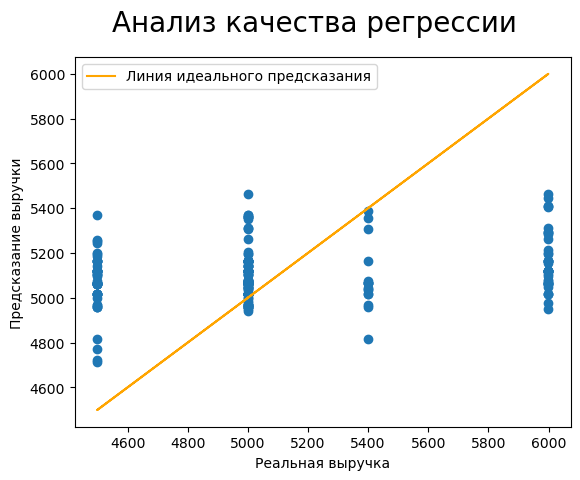

In [19]:
n = [['France', 'Germany', 'USA', 'UK'],
                    ['android', 'Mac', 'PC', 'iPhone'],
                    ['email-рассылки', 'organic', 'контекстная реклама', 'реклама у блогеров', 'соцсети'],
                    ['вечер', 'день', 'ночь', 'утро']]

X = final_df.dropna()[n[0] + n[1] + n[2]]
y = final_df.dropna()['revenue'] 

X_train, X_test, y_train, y_test = train_test_split( 
    X, y, test_size=0.3, random_state=101) 
  
model = LinearRegression() 
  
model.fit(X_train, y_train) 
  
predictions = model.predict(X_test) 

Xc = sm.add_constant(X)
model = sm.OLS(y,Xc)
rs = model.fit()
print(rs.params)
print()

kr = final_df.dropna().reset_index().drop(['index', 'sessiondurationsec'], axis=1)
rp = []
p = rs.params
c = kr.columns
s = p[0]
for i in range(len(kr['France'])):
    for j in range(1, len(p)):
        s += p[j] * kr[c[j]][i]
    rp.append(s)
    s = p[0]
    
print('mean_absolute_percentage_error:', round(mean_absolute_percentage_error(kr['revenue'], rp) * 100, 1), end='%')
print()
print('r2_score', round(r2_score(kr['revenue'], rp), 3))
print()
    
f, ax = plt.subplots()
plt.scatter(kr['revenue'], rp)
plt.plot(kr['revenue'], kr['revenue'], c='orange', label='Линия идеального предсказания')
ax.set_ylabel('Предсказание выручки')
ax.set_xlabel('Реальная выручка')
f.suptitle('Анализ качества регрессии', fontsize=20)
plt.legend()
plt.show() # выполнена сама регрессия, есть данные о коэффициентах для дальнейших выводов и построен интерпретируемый график

Была построена регрессия, где отклик это выручка, а факторы девайс, канал привлечения и регион. Были выбраны именно эти переменные, так как они дают наименьший mape, что является показателем качества регрессии.

# Проверка гипотез

In [20]:
df = dn
df['revenue'] = df['revenue'].fillna(0)
df['payment_type'] = df['payment_type'].fillna('NONE')
df['session_start'] = pd.to_datetime(df['session_start'])
df['month'] = df['session_start'].dt.month
df.head(5) # создание и преобразование переменных в датасете для проверки гипотез

,user_id,region,device,channel,session_start,sessiondurationsec,order_dt,revenue,payment_type,promo_code,part_of_day,payer,month
0,601292388085,United States,PC,organic,2019-05-01 06:56:16,782.0,NaT,0.0,NONE,1.0,утро,0,5
1,852898876338,United States,Mac,социальные сети,2019-05-01 04:30:45,251.0,NaT,0.0,NONE,1.0,ночь,0,5
2,998513020664,United States,iPhone,социальные сети,2019-05-01 18:53:42,233.0,NaT,0.0,NONE,1.0,вечер,0,5
3,240702200943,United States,Mac,социальные сети,2019-05-02 14:04:32,319.0,NaT,0.0,NONE,1.0,день,0,5
4,271758921583,United States,iPhone,социальные сети,2019-05-02 08:40:35,40.0,NaT,0.0,NONE,1.0,утро,0,5


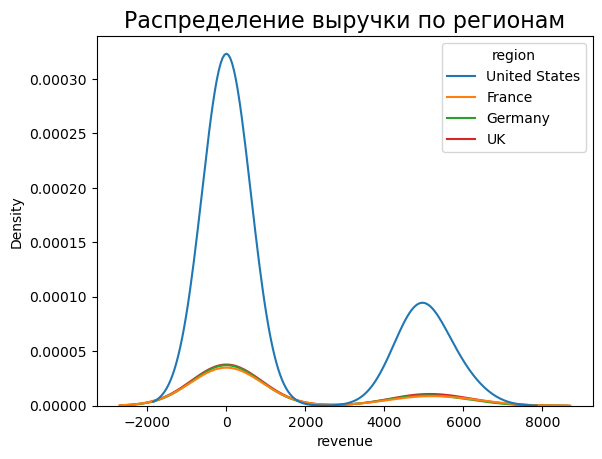

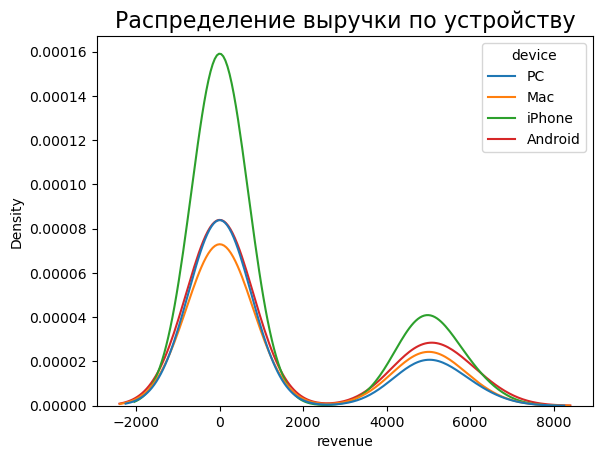

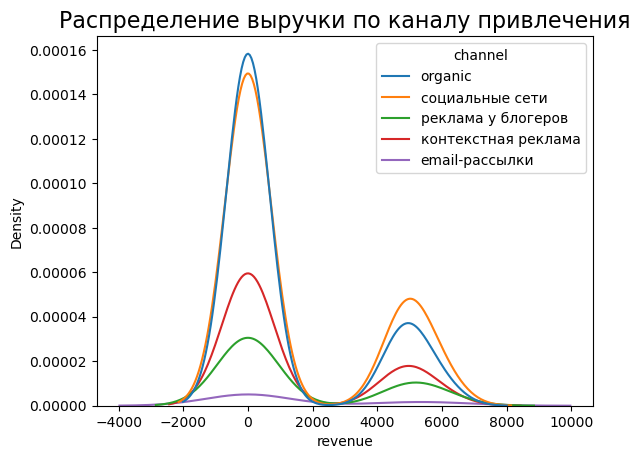

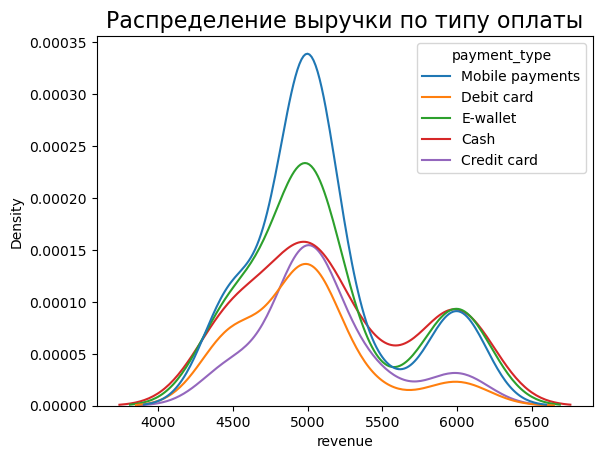

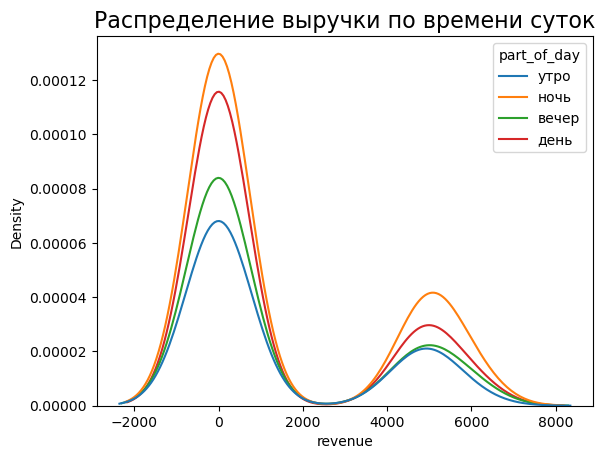

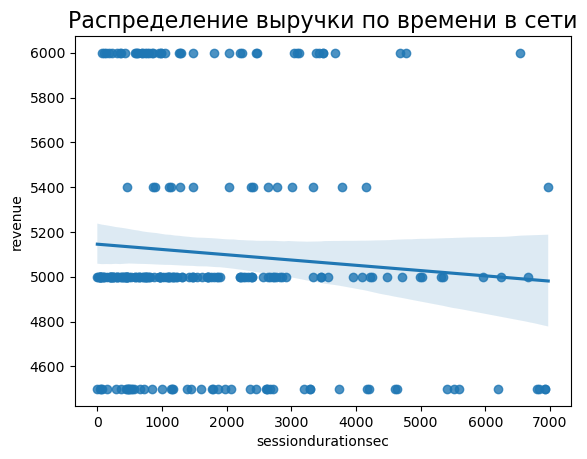

In [21]:
sns.kdeplot(data=df, x='revenue', hue='region')
plt.title('Распределение выручки по регионам', fontsize=16)
plt.show()
sns.kdeplot(data=df, x='revenue', hue='device')
plt.title('Распределение выручки по устройству', fontsize=16)
plt.show()
sns.kdeplot(data=df, x='revenue', hue='channel')
plt.title('Распределение выручки по каналу привлечения', fontsize=16)
plt.show()
sns.kdeplot(data=df[df['payment_type'] != 'NONE'], x='revenue', hue='payment_type')
plt.title('Распределение выручки по типу оплаты', fontsize=16)
plt.show()
sns.kdeplot(data=df, x='revenue', hue='part_of_day')
plt.title('Распределение выручки по времени суток', fontsize=16)
plt.show()
sns.regplot(data = df[df['revenue'] != 0], x='sessiondurationsec', y='revenue') 
plt.title('Распределение выручки по времени в сети', fontsize=16)
plt.show() 

Были построены ядерные оценки плотности, для графической проверки выборой на нормальность, что является необходимым для выбора правильного метода для проверки гипотез.

Гипотеза 1 (Влияет ли тип устройства на количество покупок в день по каждому региону?):
KruskalResult(statistic=2.7508682529704878, pvalue=0.431651867015436)
KruskalResult(statistic=4.556819390208456, pvalue=0.20727777725364077)
KruskalResult(statistic=2.233793614971649, pvalue=0.525322791466948)
KruskalResult(statistic=14.95353107747731, pvalue=0.0018567935346291446)
р-уровень меньше 0.1 только в регионе "UK". Это говорит о том, что текущих данных хватает, чтобы сделать вывод о количестве покупок в этом регионе.

гипотеза 1:



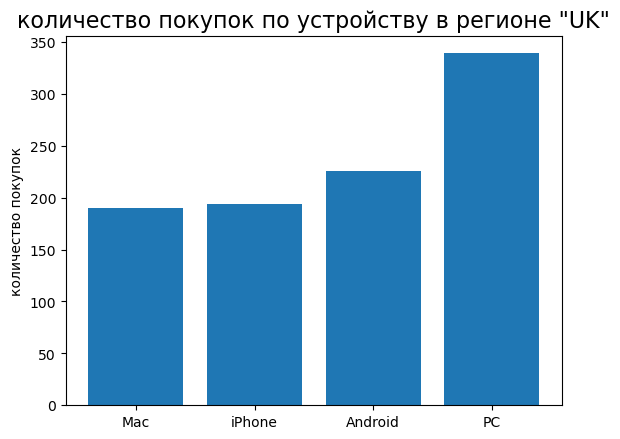




Гипотеза 2 (Влияет ли тип рекламного канала на количество покупок в день по каждому региону?):
KruskalResult(statistic=13.751138711540271, pvalue=0.008133175229576857)
KruskalResult(statistic=59.78439259855026, pvalue=3.21982954465549e-12)
KruskalResult(statistic=14.06004965293484, pvalue=0.007105847752626818)
KruskalResult(statistic=14.615538307848043, pvalue=0.005568786934580692)
р-уровень меньше 0.1 во всех регионах. Это говорит о том, что текущих данных хватает, чтобы сделать вывод о различии количества покупок в этих регионах.
Гипотеза 2:



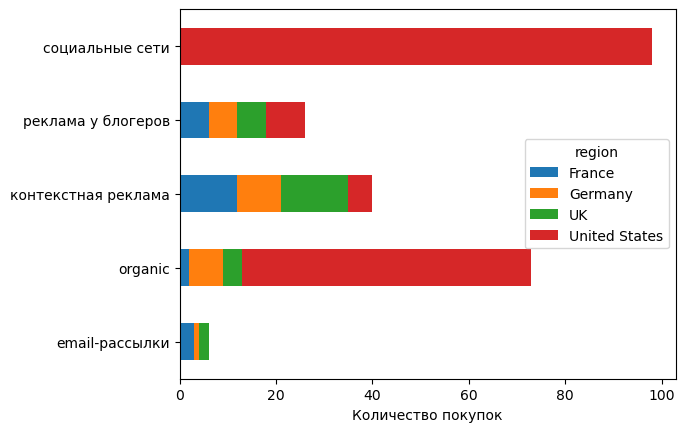


Гипотеза 3 (Проверить гипотезу о том, что средний чек отличается в зависимости от региона?):
Результаты теста Шапиро-Уилка - 0.0 ,  0.0004 ,  0.0007 ,  0.0001
Используем метод Краскела-Уоллеса: KruskalResult(statistic=3.663792618702798, pvalue=0.30013179318508565)
р-уровень больше 0.1. Это говорит о том, что текущих данных не хватает, чтобы сделать вывод о различии средних.



Гипотеза 4 (Проверить гипотезу о том, что средний чек отличается в зависимости от рекламного канала?):
Результаты теста Шапиро-Уилка - 0.0 ,  0.0 ,  0.0 ,  0.0 ,  0.0288
Используем метод Краскела-Уоллеса: KruskalResult(statistic=4.764142907619247, pvalue=0.31236494604423576)
р-уровень больше 0.1. Это говорит о том, что текущих данных не хватает, чтобы сделать вывод о различии средних.



Гипотеза 5 (Проверить гипотезу о том, что средний чек отличается в зависимости от времени суток?):
Результаты теста Шапиро-Уилка - 0.0 ,  0.0 ,  0.0 ,  0.0
Используем метод Краскела-Уоллеса: KruskalResult(statistic=4.65658474092

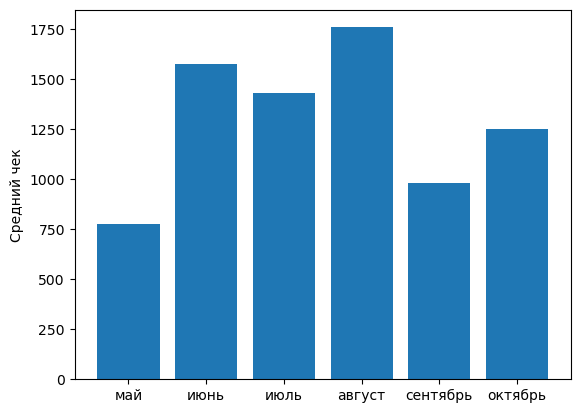




Гипотеза 8 (Проверить гипотезу о том, что средний чек отличается в зависимости от типа оплаты?):
Результаты теста Шапиро-Уилка - ,  0.0 ,  0.0 ,  0.0 ,  0.0 ,  0.0
Используем метод Краскела-Уоллеса: KruskalResult(statistic=2.7636024848451526, pvalue=0.5981317590515076)
р-уровень больше 0.1. Это говорит о том, что текущих данных не хватает, чтобы сделать вывод о различии средних.



Гипотеза 9 (различие среднего чека в зависимости от канала привлечения и региона):
KruskalResult(statistic=8.250670352589646, pvalue=0.08281556491797423)
KruskalResult(statistic=60.63252929642721, pvalue=2.1359127387524002e-12)
KruskalResult(statistic=14.086287570559746, pvalue=0.0070246930374968115)
KruskalResult(statistic=14.356382094968296, pvalue=0.006240343408730825)
р-уровень меньше 0.1 во всех регионах. Это говорит о том, что текущих данных хватает, чтобы сделать вывод о различии среднего чека в этих регионах.

Гипотеза 9



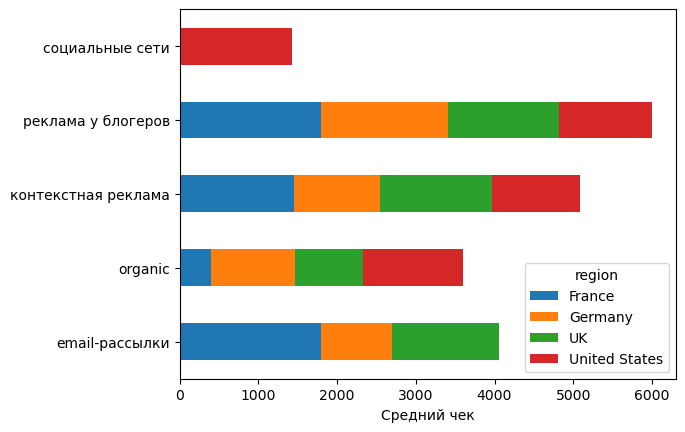

In [27]:
df['revenue'] = df.revenue.dropna()

df1 = df
df1['revenue'] = df1.revenue.fillna(0)
print('Гипотеза 1 (Влияет ли тип устройства на количество покупок в день по каждому региону?):')
df['session_start'] = pd.to_datetime(df['session_start']).dt.date
df_iPhone =  pd.DataFrame()
df_iPhone['United States'] = df[(df['region'] == 'United States') & (df['device'] == 'iPhone')].groupby('session_start')['payer'].sum()
df_iPhone['France'] = df[(df['region'] == 'France') & (df['device'] == 'iPhone')].groupby('session_start')['payer'].sum()
df_iPhone['Germany'] = df[(df['region'] == 'Germany') & (df['device'] == 'iPhone')].groupby('session_start')['payer'].sum()
df_iPhone['UK'] = df[(df['region'] == 'UK') & (df['device'] == 'iPhone')].groupby('session_start')['payer'].sum() 
df_Android =  pd.DataFrame()
df_Android['United States'] = df[(df['region'] == 'United States') & (df['device'] == 'Android')].groupby('session_start')['payer'].sum()
df_Android['France'] = df[(df['region'] == 'France') & (df['device'] == 'Android')].groupby('session_start')['payer'].sum()
df_Android['Germany'] = df[(df['region'] == 'Germany') & (df['device'] == 'Android')].groupby('session_start')['payer'].sum()
df_Android['UK'] = df[(df['region'] == 'UK') & (df['device'] == 'Android')].groupby('session_start')['payer'].sum()
df_Mac =  pd.DataFrame()
df_Mac['United States'] = df[(df['region'] == 'United States') & (df['device'] == 'Mac')].groupby('session_start')['payer'].sum()
df_Mac['France'] = df[(df['region'] == 'France') & (df['device'] == 'Mac')].groupby('session_start')['payer'].sum()
df_Mac['Germany'] = df[(df['region'] == 'Germany') & (df['device'] == 'Mac')].groupby('session_start')['payer'].sum()
df_Mac['UK'] = df[(df['region'] == 'UK') & (df['device'] == 'Mac')].groupby('session_start')['payer'].sum()
df_PC =  pd.DataFrame()
df_PC['United States'] = df[(df['region'] == 'United States') & (df['device'] == 'PC')].groupby('session_start')['payer'].sum()
df_PC['France'] = df[(df['region'] == 'France') & (df['device'] == 'PC')].groupby('session_start')['payer'].sum()
df_PC['Germany'] = df[(df['region'] == 'Germany') & (df['device'] == 'PC')].groupby('session_start')['payer'].sum()
df_PC['UK'] = df[(df['region'] == 'UK') & (df['device'] == 'PC')].groupby('session_start')['payer'].sum()
df_iPhone = df_iPhone.fillna(0)
df_Android = df_Android.fillna(0)
df_Mac = df_Mac.fillna(0)
df_PC = df_PC.fillna(0)
print(stats.kruskal(df_iPhone['United States'], df_Android['United States'], df_Mac['United States'], df_PC['United States']))
print(stats.kruskal(df_iPhone['France'], df_Android['France'], df_Mac['France'], df_PC['France']))
print(stats.kruskal(df_iPhone['Germany'], df_Android['Germany'], df_Mac['Germany'], df_PC['Germany']))
print(stats.kruskal(df_iPhone['UK'], df_Android['UK'], df_Mac['UK'], df_PC['UK']))
print('р-уровень меньше 0.1 только в регионе "UK". Это говорит о том, что текущих данных хватает, чтобы сделать вывод о количестве покупок в этом регионе.')
print()
print('гипотеза 1:')
plt.bar(dn[dn['region'] == 'UK'].groupby('device', as_index=False)['revenue'].count().sort_values('revenue')['device'],
        dn.groupby('device', as_index=False)['revenue'].count().sort_values('revenue')['revenue'])
plt.ylabel("количество покупок")
plt.title('количество покупок по устройству в регионе "UK"', fontsize=16)
print()
plt.show()

print()
print()
print()

print('Гипотеза 2 (Влияет ли тип рекламного канала на количество покупок в день по каждому региону?):')
dn['session_start'] = pd.to_datetime(dn['session_start']).dt.date

organic = pd.DataFrame()
organic['United States'] = dn[(dn['region'] == 'United States') & (dn['channel'] == 'organic')].groupby('session_start')['payer'].sum()
organic['France'] = dn[(dn['region'] == 'France') & (dn['channel'] == 'organic')].groupby('session_start')['payer'].sum()
organic['Germany'] = dn[(dn['region'] == 'Germany') & (dn['channel'] == 'organic')].groupby('session_start')['payer'].sum()
organic['UK'] = dn[(dn['region'] == 'UK') & (dn['channel'] == 'organic')].groupby('session_start')['payer'].sum()
organic = organic.fillna(0)

seti = pd.DataFrame()
seti['United States'] = dn[(dn['region'] == 'United States') & (dn['channel'] == 'социальные сети')].groupby('session_start')['payer'].sum()
seti['France'] = dn[(dn['region'] == 'France') & (dn['channel'] == 'социальные сети')].groupby('session_start')['payer'].sum()
seti['Germany'] = dn[(dn['region'] == 'Germany') & (dn['channel'] == 'социальные сети')].groupby('session_start')['payer'].sum()
seti['UK'] = dn[(dn['region'] == 'UK') & (dn['channel'] == 'социальные сети')].groupby('session_start')['payer'].sum()
seti = seti.fillna(0)

bloger = pd.DataFrame()
bloger['United States'] = dn[(dn['region'] == 'United States') & (dn['channel'] == 'реклама у блогеров')].groupby('session_start')['payer'].sum()
bloger['France'] = dn[(dn['region'] == 'France') & (dn['channel'] == 'реклама у блогеров')].groupby('session_start')['payer'].sum()
bloger['Germany'] = dn[(dn['region'] == 'Germany') & (dn['channel'] == 'реклама у блогеров')].groupby('session_start')['payer'].sum()
bloger['UK'] = dn[(dn['region'] == 'UK') & (dn['channel'] == 'реклама у блогеров')].groupby('session_start')['payer'].sum()
bloger = bloger.fillna(0)

kontext = pd.DataFrame()
kontext['United States'] = dn[(dn['region'] == 'United States') & (dn['channel'] == 'контекстная реклама')].groupby('session_start')['payer'].sum()
kontext['France'] = dn[(dn['region'] == 'France') & (dn['channel'] == 'контекстная реклама')].groupby('session_start')['payer'].sum()
kontext['Germany'] = dn[(dn['region'] == 'Germany') & (dn['channel'] == 'контекстная реклама')].groupby('session_start')['payer'].sum()
kontext['UK'] = dn[(dn['region'] == 'UK') & (dn['channel'] == 'контекстная реклама')].groupby('session_start')['payer'].sum()
kontext = kontext.fillna(0)

email = pd.DataFrame()
email['United States'] = dn[(dn['region'] == 'United States') & (dn['channel'] == 'email-рассылки')].groupby('session_start')['payer'].sum()
email['France'] = dn[(dn['region'] == 'France') & (dn['channel'] == 'email-рассылки')].groupby('session_start')['payer'].sum()
email['Germany'] = dn[(dn['region'] == 'Germany') & (dn['channel'] == 'email-рассылки')].groupby('session_start')['payer'].sum()
email['UK'] = dn[(dn['region'] == 'UK') & (dn['channel'] == 'email-рассылки')].groupby('session_start')['payer'].sum()
email = email.fillna(0) 
print(stats.kruskal(seti['United States'], organic['United States'], kontext['United States'], email['United States'], bloger['United States']))
print(stats.kruskal(seti['France'], organic['France'], kontext['France'], email['France'], bloger['France']))
print(stats.kruskal(seti['Germany'], organic['Germany'], kontext['Germany'], email['Germany'], bloger['Germany']))
print(stats.kruskal(seti['UK'], organic['UK'], kontext['UK'], email['UK'], bloger['UK']))
print('р-уровень меньше 0.1 во всех регионах. Это говорит о том, что текущих данных хватает, чтобы сделать вывод о различии количества покупок в этих регионах.')
print('Гипотеза 2:')
print()
k = dn[dn['payer'] == 1].groupby(['channel'])['region'].value_counts().unstack()
k.index = ['email-рассылки', 'organic', 'контекстная реклама', 'реклама у блогеров', 'социальные сети']
k.plot(kind='barh', stacked=True)
plt.xlabel("Количество покупок")
plt.show() 
print()

print('Гипотеза 3 (Проверить гипотезу о том, что средний чек отличается в зависимости от региона?):')
df31 = df[(df['region'] == 'United States') & (df['revenue'] != 0)]
df32 = df[(df['region'] == 'France') & (df['revenue'] != 0)]
df33 = df[(df['region'] == 'Germany') & (df['revenue'] != 0)]
df34 = df[(df['region'] == 'UK') & (df['revenue'] != 0)]
print('Результаты теста Шапиро-Уилка -', round(shapiro(df31['revenue'])[1], 4), ', ', round(shapiro(df32['revenue'])[1], 4), ', ', round(shapiro(df33['revenue'])[1], 4), ', ', round(shapiro(df34['revenue'])[1], 4))
print('Используем метод Краскела-Уоллеса:', stats.kruskal(df31['revenue'], df32['revenue'], df33['revenue'], df34['revenue']))
print('р-уровень больше 0.1. Это говорит о том, что текущих данных не хватает, чтобы сделать вывод о различии средних.')

print()
print()
print()

print('Гипотеза 4 (Проверить гипотезу о том, что средний чек отличается в зависимости от рекламного канала?):')
df41 = df[(df['channel'] == 'социальные сети') & (df['revenue'] != 0)]
df42 = df[(df['channel'] == 'organic') & (df['revenue'] != 0)]
df43 = df[(df['channel'] == 'контекстная реклама') & (df['revenue'] != 0)]
df44 = df[(df['channel'] == 'реклама у блогеров') & (df['revenue'] != 0)]
df45 = df[(df['channel'] == 'email-рассылки') & (df['revenue'] != 0)]
print('Результаты теста Шапиро-Уилка -', round(shapiro(df41['revenue'])[1], 4), ', ', round(shapiro(df42['revenue'])[1], 4), ', ', round(shapiro(df43['revenue'])[1], 4), ', ', round(shapiro(df44['revenue'])[1], 4), ', ', round(shapiro(df45['revenue'])[1], 4))
print('Используем метод Краскела-Уоллеса:', stats.kruskal(df41['revenue'], df42['revenue'], df43['revenue'], df44['revenue'], df45['revenue']))
print('р-уровень больше 0.1. Это говорит о том, что текущих данных не хватает, чтобы сделать вывод о различии средних.')

print()
print()
print()

print('Гипотеза 5 (Проверить гипотезу о том, что средний чек отличается в зависимости от времени суток?):')
df51 = df[(df['part_of_day'] == 'ночь') & (df['revenue'] != 0)]
df52 = df[(df['part_of_day'] == 'день') & (df['revenue'] != 0)]
df53 = df[(df['part_of_day'] == 'вечер') & (df['revenue'] != 0)]
df54 = df[(df['part_of_day'] == 'утро') & (df['revenue'] != 0)]
print('Результаты теста Шапиро-Уилка -', round(shapiro(df51['revenue'])[1], 4), ', ', round(shapiro(df52['revenue'])[1], 4), ', ', round(shapiro(df53['revenue'])[1], 4), ', ', round(shapiro(df54['revenue'])[1], 4))
print('Используем метод Краскела-Уоллеса:', stats.kruskal(df51['revenue'], df52['revenue'], df53['revenue'], df54['revenue']))
print('р-уровень больше 0.1. Это говорит о том, что текущих данных не хватает, чтобы сделать вывод о различии средних.')

print()
print()
print()

print('Гипотеза 6 (Есть ли взаимосвязь между продолжительностью сессии с суммой покупок?):')
print('Результаты теста Шапиро-Уилка -', round(shapiro(df[df['revenue'] != 0]['sessiondurationsec'])[1], 4), ', ', round(shapiro(df[df['revenue'] != 0]['revenue'])[1], 4))
print('метод корреляции спирмана : ', spearmanr(df['sessiondurationsec'], df['revenue']))
print('Поскольку p-значение не меньше α = 0.05, можно сделать вывод, что корреляция не является статистически значимой.')

print()
print()
print()

print('Гипотеза 7 (Проверить гипотезу о том, что средний чек отличается в зависимости от месяца покупки?):')
df71 = df[(df['month'] == 5)]
df72 = df[(df['month'] == 6)]
df73 = df[(df['month'] == 7)]
df74 = df[(df['month'] == 8)]
df75 = df[(df['month'] == 9)]
df76 = df[(df['month'] == 10)]
print()
dn['session_start'] = pd.to_datetime(dn.session_start)
print('Результаты теста Шапиро-Уилка -', round(shapiro(df71['revenue'])[1], 4), ', ', round(shapiro(df72['revenue'])[1], 4), ', ', round(shapiro(df73['revenue'])[1], 4), ', ', round(shapiro(df74['revenue'])[1], 4), ', ', round(shapiro(df75['revenue'])[1], 4), ', ', round(shapiro(df76['revenue'])[1], 4))
print('Используем метод Краскела-Уоллеса:', stats.kruskal(df71['revenue'], df72['revenue'], df73['revenue'], df74['revenue'], df75['revenue'], df76['revenue']))
print('р-уровень меньше 0.1. Это говорит о том, что текущих данных хватает, чтобы сделать вывод о различии средних.')
dn['month'] = dn.session_start.dt.month
k = dn.groupby('month')['revenue'].mean()
plt.bar(['май', 'июнь', 'июль', 'август', 'сентябрь', 'октябрь'], k)
plt.ylabel("Средний чек")
plt.show()

print()
print()
print()

print('Гипотеза 8 (Проверить гипотезу о том, что средний чек отличается в зависимости от типа оплаты?):')
df82 = df[(df['payment_type'] == 'Mobile payments') & (df['revenue'] != 0)]
df83 = df[(df['payment_type'] == 'Cash') & (df['revenue'] != 0)]
df84 = df[(df['payment_type'] == 'E-wallet') & (df['revenue'] != 0)]
df85 = df[(df['payment_type'] == 'Debit card') & (df['revenue'] != 0)]
df86 = df[(df['payment_type'] == 'Credit card') & (df['revenue'] != 0)]
print('Результаты теста Шапиро-Уилка -', ', ', round(shapiro(df82['revenue'])[1], 4), ', ', round(shapiro(df83['revenue'])[1], 4), ', ', round(shapiro(df84['revenue'])[1], 4), ', ', round(shapiro(df85['revenue'])[1], 4), ', ', round(shapiro(df86['revenue'])[1], 4))
print('Используем метод Краскела-Уоллеса:', stats.kruskal(df82['revenue'], df83['revenue'], df84['revenue'], df85['revenue'], df86['revenue']))
print('р-уровень больше 0.1. Это говорит о том, что текущих данных не хватает, чтобы сделать вывод о различии средних.')

print()
print()
print()

print('Гипотеза 9 (различие среднего чека в зависимости от канала привлечения и региона):')
organic = pd.DataFrame()
organic['United States'] = dn[(dn['region'] == 'United States') & (dn['channel'] == 'organic')].groupby('session_start')['revenue'].mean()
organic['France'] = dn[(dn['region'] == 'France') & (dn['channel'] == 'organic')].groupby('session_start')['revenue'].mean()
organic['Germany'] = dn[(dn['region'] == 'Germany') & (dn['channel'] == 'organic')].groupby('session_start')['revenue'].mean()
organic['UK'] = dn[(dn['region'] == 'UK') & (dn['channel'] == 'organic')].groupby('session_start')['revenue'].mean()
organic = organic.fillna(0)

seti = pd.DataFrame()
seti['United States'] = dn[(dn['region'] == 'United States') & (dn['channel'] == 'социальные сети')].groupby('session_start')['revenue'].mean()
seti['France'] = dn[(dn['region'] == 'France') & (dn['channel'] == 'социальные сети')].groupby('session_start')['revenue'].mean()
seti['Germany'] = dn[(dn['region'] == 'Germany') & (dn['channel'] == 'социальные сети')].groupby('session_start')['revenue'].mean()
seti['UK'] = dn[(dn['region'] == 'UK') & (dn['channel'] == 'социальные сети')].groupby('session_start')['revenue'].mean()
seti = seti.fillna(0)

bloger = pd.DataFrame()
bloger['United States'] = dn[(dn['region'] == 'United States') & (dn['channel'] == 'реклама у блогеров')].groupby('session_start')['revenue'].mean()
bloger['France'] = dn[(dn['region'] == 'France') & (dn['channel'] == 'реклама у блогеров')].groupby('session_start')['revenue'].mean()
bloger['Germany'] = dn[(dn['region'] == 'Germany') & (dn['channel'] == 'реклама у блогеров')].groupby('session_start')['revenue'].mean()
bloger['UK'] = dn[(dn['region'] == 'UK') & (dn['channel'] == 'реклама у блогеров')].groupby('session_start')['revenue'].mean()
bloger = bloger.fillna(0)

kontext = pd.DataFrame()
kontext['United States'] = dn[(dn['region'] == 'United States') & (dn['channel'] == 'контекстная реклама')].groupby('session_start')['revenue'].mean()
kontext['France'] = dn[(dn['region'] == 'France') & (dn['channel'] == 'контекстная реклама')].groupby('session_start')['revenue'].mean()
kontext['Germany'] = dn[(dn['region'] == 'Germany') & (dn['channel'] == 'контекстная реклама')].groupby('session_start')['revenue'].mean()
kontext['UK'] = dn[(dn['region'] == 'UK') & (dn['channel'] == 'контекстная реклама')].groupby('session_start')['revenue'].mean()
kontext = kontext.fillna(0)

email = pd.DataFrame()
email['United States'] = dn[(dn['region'] == 'United States') & (dn['channel'] == 'email-рассылки')].groupby('session_start')['revenue'].mean()
email['France'] = dn[(dn['region'] == 'France') & (dn['channel'] == 'email-рассылки')].groupby('session_start')['revenue'].mean()
email['Germany'] = dn[(dn['region'] == 'Germany') & (dn['channel'] == 'email-рассылки')].groupby('session_start')['revenue'].mean()
email['UK'] = dn[(dn['region'] == 'UK') & (dn['channel'] == 'email-рассылки')].groupby('session_start')['revenue'].mean()
email = email.fillna(0) 
print(stats.kruskal(seti['United States'], organic['United States'], kontext['United States'], email['United States'], bloger['United States']))
print(stats.kruskal(seti['France'], organic['France'], kontext['France'], email['France'], bloger['France']))
print(stats.kruskal(seti['Germany'], organic['Germany'], kontext['Germany'], email['Germany'], bloger['Germany']))
print(stats.kruskal(seti['UK'], organic['UK'], kontext['UK'], email['UK'], bloger['UK']))
print('р-уровень меньше 0.1 во всех регионах. Это говорит о том, что текущих данных хватает, чтобы сделать вывод о различии среднего чека в этих регионах.')
print()
print('Гипотеза 9')
print()
k = dn.groupby(['channel', 'region'])['revenue'].mean().unstack()
k.index = ['email-рассылки', 'organic', 'контекстная реклама', 'реклама у блогеров', 'социальные сети']
k.plot(kind='barh', stacked=True)
plt.xlabel("Средний чек")
plt.show() 
# проверка гипотез, графики были построены только по гипотезам, имеющим статистическую значимость

# Гипотезы имеющие статистическую значимость - 2, 7, 9 и частично 1 (только один регион)

## Ссылка на дашборд - https://datalens.yandex.ru/6s06pq4fkhd2v-internet-magazin